# Monte Carlo 2 notebook

## Monte Carlo integration

For functions that have sharp features, using the trapezoid or Simpson's method might not work well or require too many points to maintain accuracy. In those situations, the Monte Carlo method can be beneficial.

Consider the integral:

$$
I = \int_0^2\sin^2\left(\frac{1}{x(2-x)}\right)
$$

We can approximate the integral using:

$$
I \approx \frac{kA}{N}
$$

where:
- $N$ is the number of randomly generated point in the region $0\leq x \leq 2$ and $0 \leq f(x) \leq 1$. 
- $A$ is the area of the region.
- $k$ is the number of randomly generated point that falls below $f(x) = \sin^2\left(\frac{1}{x(2-x)}\right)$

The value of the integral with N = 100 is 1.6400 +/- 0.0768.
The value of the integral with N = 1000 is 1.4660 +/- 0.0280.
The value of the integral with N = 10000 is 1.4424 +/- 0.0090.
The value of the integral with N = 100000 is 1.4537 +/- 0.0028.


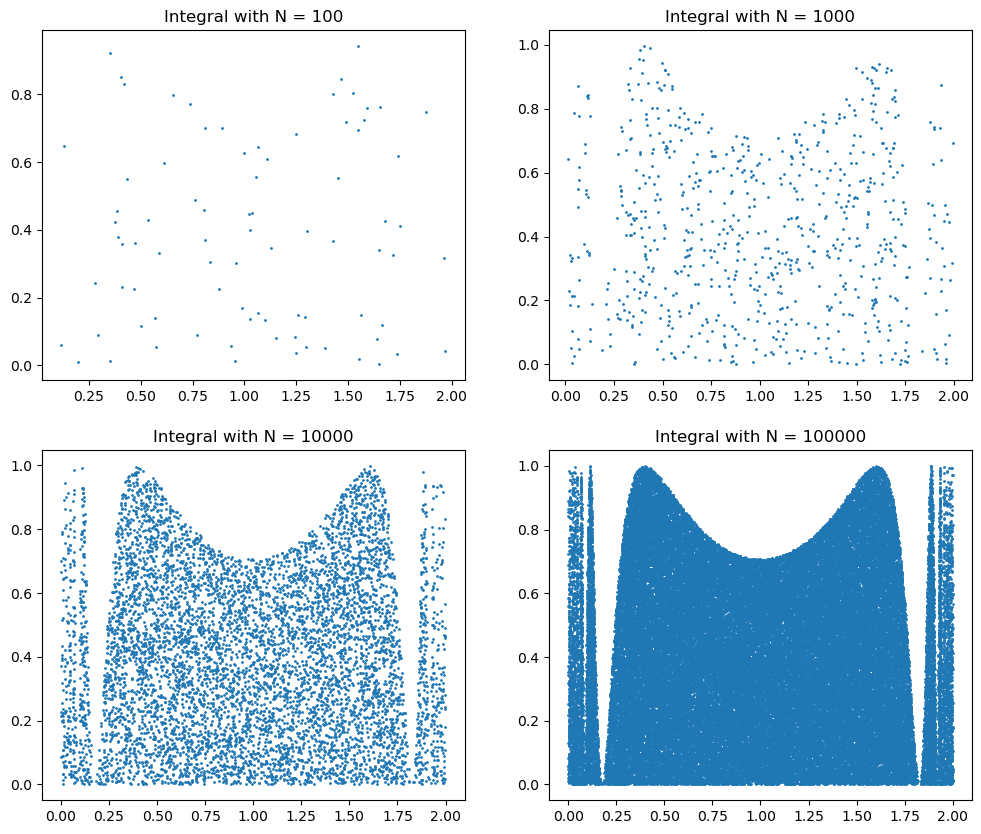

In [18]:
import numpy as np 
import matplotlib.pyplot as plt 

# Number of points
N = [100, 1000, 10000, 100000]

def fx(x):
    return np.sin(1/(x*(2-x)))**2

def monte_carlo_integration(f, x_min, x_max, y_min, y_max, N):
    # Integral of function f between x_min and x_max with N points. f(x) is bound by y_min and y_max

    integral = 0

    rng = np.random.default_rng()

    x_array = []
    y_array = []

    A = (y_max-y_min)*(x_max-x_min)

    for i in range(N):
        x = rng.uniform(x_min, x_max)
        y = rng.uniform(y_min, y_max)

        if y < f(x):
            integral += A/N
            x_array.append(x)
            y_array.append(y)

    return integral, x_array, y_array 

def calc_error(I, x_min, x_max, y_min, y_max, N):
    A = (x_max-x_min)*(y_max-y_min)
    return np.sqrt(I*(A-I)/N)

fig, axes = plt.subplots(2, 2, figsize=(12,10))
for k, n in enumerate(N):
    integral, x_array, y_array = monte_carlo_integration(fx, 0.0, 2.0, 0.0, 1.0, n)
    error = calc_error(integral, 0.0, 2.0, 0.0, 1.0, n)
    print(f"The value of the integral with N = {n} is {integral:.4f} +/- {error:.4f}.")
    i = k // 2
    j = k % 2
    axes[i, j].scatter(x_array, y_array, s=1)
    axes[i, j].set_title(f"Integral with N = {n}")
plt.show()

## Mean value method

If we want to calculate the following integral:

$$
I = \int_a^b f(x) dx
$$

is related to the average:

$$
\langle f(x) \rangle = \frac{1}{b-a}\int_a^b f(x) dx
$$

Hence, 

$$
I = (b-a) \langle f(x) \rangle = \frac{(b-a)}{N}\sum_{i=1}^N f(x_i)
$$

The strategy is to calculate $N$ random of $x_i$, calculate $f(x_i)$, and compute the average.

We can apply this method to the same system as above and compare the results.

In [13]:
def mean_value_integration(f, x_min, x_max, N):
    integral = 0.0

    fx = np.empty(N, dtype='float')

    rng = np.random.default_rng()

    for i in range(N):
        fx[i] = f(rng.uniform(x_min, x_max))

    return (x_max-x_min)*np.sum(fx)/N, (x_max-x_min)*np.std(fx)/np.sqrt(N)

for k, n in enumerate(N):
    integral_mc, x_array, y_array = monte_carlo_integration(fx, 0.0, 2.0, 0.0, 1.0, n)
    error_mc = calc_error(integral, 0.0, 2.0, 0.0, 1.0, n)
    integral_mv, error_mv = mean_value_integration(fx, 0.0, 2.0, n)
    
    print(f"N = {n}: Monte Carlo integral = {integral_mc:.4f} +/- {error_mc:.4f}. Mean value integral = {integral_mv:.4f} +/- {error_mv:.4f}.")

N = 100: Monte Carlo integral = 1.3200 +/- 0.0892. Mean value integral = 1.4703 +/- 0.0484.
N = 1000: Monte Carlo integral = 1.4580 +/- 0.0282. Mean value integral = 1.4393 +/- 0.0175.
N = 10000: Monte Carlo integral = 1.4310 +/- 0.0089. Mean value integral = 1.4457 +/- 0.0053.
N = 100000: Monte Carlo integral = 1.4467 +/- 0.0028. Mean value integral = 1.4538 +/- 0.0017.


## Integral in many dimensions

Consider calculating the moment of inertia of a solid is a simple equation but the integral can 
be complicated with weirdly shaped solids. Below, we calculate the moment of inertia about the 
z-axis of a disk with holes in it:

$$
I = \int \rho^2 dm = \int_V \rho^2 \sigma(\vec{r}) dV
$$

The volume is a cylinder of radius 2 and height 1 with 2 cylindrical holes of radius 0.5 at 
$\rho = 1$ and $\phi = 0$ and $\phi = \pi$. The mass density is given by 

$$
\sigma(\rho, \phi, z) = \rho\cos^2(\phi)
$$

The moment of inertia is 18.31755260350139 kg m^2.


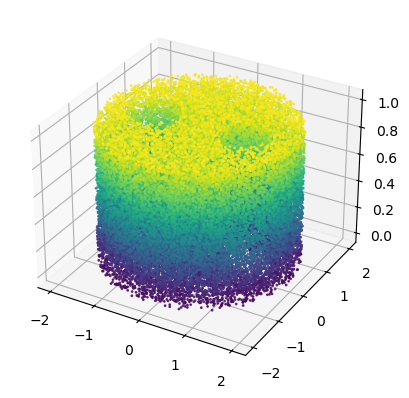

In [31]:
# Check whether a point is within the volume
def cylinder_shape(rho, phi, z):
    if rho > 2:
        return False
    
    if z < 0:
        return False

    if z > 1: 
        return False

    if (rho*np.cos(phi)-1)**2+(rho*np.sin(phi))**2 < 0.5**2:
        return False

    if (rho*np.cos(phi)+1)**2+(rho*np.sin(phi))**2 < 0.5**2:
        return False

    return True

# Number of points
N = 100000

# Set up rng
rng = np.random.default_rng()

# Values to calculate
integral = 0.0 
x_array = []
y_array = []
z_array = []

# Run through N random locations
for i in range(N):
    x = rng.uniform(-2.2, 2.2)
    y = rng.uniform(-2.2, 2.2)
    z = rng.uniform(-0.1, 1.1)

    rho = np.sqrt(x**2 + y**2)
    phi = np.arctan2(y, x)

    if cylinder_shape(rho, phi, z) == True:
        integral += rho**3*np.cos(phi)**2
        x_array.append(x)
        y_array.append(y)
        z_array.append(z)

integral = integral * 23.232 / N

print(f"The moment of inertia is {integral} kg m^2.")

# Plot the point distribution to verify the cylinder shape
fig1 = plt.figure()
ax1 = fig1.add_subplot(projection='3d')
ax1.scatter(x_array, y_array, z_array, c=z_array, cmap='viridis', s=1, alpha=0.8)

plt.show()